# CT4101 Milestone 4: Final Evaluation
**Project:** Predicting whether a Pokémon is Legendary (binary classification)
**Author:** Cian Flanagan (student number 23391703)

This notebook builds on `01_data_audit_and_baseline.ipynb` and `02_model_comparison.ipynb`. It uses the same split, the same preprocessing and the same cross-validation protocol. In this notebook I tune the models with nested cross-validation and choose the final model. The held-out test set is **not used in this part**; it is only opened once, later in this notebook, after the final model is declared.

**Assistance declaration:** Claude (an AI assistant) drafted the code and explanations. I added them to this notebook section by section, ran and tested them, and reviewed them myself.

## 1. Setup and the same split as before
This cell imports the libraries, sets the fixed random seed (42) and finds the project folder. The project folder is the one that contains `data/pokemon.csv`, so the notebook works whether it is run from the project folder or from `notebooks/`.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

# Find the project folder: it is the folder that contains data/pokemon.csv
ROOT = Path.cwd()
if not (ROOT / "data" / "pokemon.csv").exists():
    ROOT = ROOT.parent
DATA_PATH = ROOT / "data" / "pokemon.csv"
FIG_DIR = ROOT / "reports" / "figures"
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Cannot find {DATA_PATH}. Save this notebook inside the project's notebooks/ folder, next to data/pokemon.csv.")
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Using data file:", DATA_PATH)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

Using data file: c:\Users\Cian\Downloads\233891703_2 (1)\ct4101-pokemon-legendary-classification\data\pokemon.csv


This cell loads the data and recreates exactly the same stratified 80/20 split as Milestones 2 and 3. The `assert` stops the notebook with an error if the split ever changes. The test set (`X_test`, `y_test`) is created here but stays locked until the final evaluation.

In [2]:
df = pd.read_csv(DATA_PATH)

num_cols = ["height_dm", "weight_hg", "hp", "attack", "defense",
            "special_attack", "special_defense", "speed"]
cat_cols = ["type_1", "type_2", "generation"]
target_col = "is_legendary"

X = df[num_cols + cat_cols].copy()
X["type_2"] = X["type_2"].fillna("none")
y = df[target_col].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)

assert (len(X_train), y_train.sum(), len(X_test), y_test.sum()) == (1080, 96, 271, 24)
print(f"Train: {len(X_train)} rows, {y_train.sum()} Legendary | Test: {len(X_test)} rows, {y_test.sum()} Legendary (locked)")

Train: 1080 rows, 96 Legendary | Test: 271 rows, 24 Legendary (locked)


## 2. Preprocessing, cross-validation and the evaluation helper
This cell is the same as before. Numeric columns get median imputation and scaling; categorical columns get a "none" fill and one-hot encoding. Everything sits inside a pipeline, so it is only fitted on the training part of each fold, which avoids data leakage. `cv` is the 5-fold stratified cross-validation used for every comparison, and `evaluate` returns the mean scores for any model.

In [3]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="none")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, num_cols),
    ("cat", categorical_pipe, cat_cols),
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
}

def make_pipeline(model):
    return Pipeline([("prep", preprocess), ("model", model)])

def evaluate(name, estimator):
    """Cross-validate on the training set and return one row of mean metrics."""
    res = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    row["f1_std"] = res["test_f1"].std()
    return row

## 3. Recap: default settings from Milestone 3
This cell re-runs the six default models so this notebook is complete on its own and I can compare them directly with the tuned versions. The numbers should match Milestone 3 (Dummy 0.000, Dummy stratified 0.070, Logistic Regression 0.535, KNN 0.457, Decision Tree 0.597, Random Forest 0.637 for F1).

In [4]:
default_models = {
    "Dummy (most_frequent)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=RANDOM_STATE),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "KNN (default, k=5)": KNeighborsClassifier(),
    "Decision Tree (default)": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest (default)": RandomForestClassifier(random_state=RANDOM_STATE),
}

defaults = pd.DataFrame(
    [evaluate(name, make_pipeline(model)) for name, model in default_models.items()]
).set_index("model").round(3)
defaults

,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
Dummy (most_frequent),0.911,0.500,0.000,0.000,0.000,0.000
Dummy (stratified),0.853,0.496,0.080,0.063,0.070,0.024
Logistic Regression,0.934,0.714,0.717,0.447,0.535,0.129
"KNN (default, k=5)",0.924,0.677,0.624,0.376,0.457,0.104
Decision Tree (default),0.926,0.786,0.597,0.615,0.597,0.055
Random Forest (default),0.951,0.743,0.917,0.491,0.637,0.079


## 4. Tuning with nested cross-validation

**Why nested?** If I pick the best settings using the same folds I then report, the score is slightly optimistic, because the settings were chosen to suit those folds. In nested cross-validation, the *outer* 5 folds are only used for scoring. Inside each outer training part, an *inner* 5-fold `GridSearchCV` tries every setting and keeps the best one by F1. That chosen model is then scored on the outer fold it has never seen. The outer score is an honest estimate of "tune, then predict new data".

**Proportionate tuning:** small grids only, because there are just 96 Legendary Pokémon in training and a large search would overfit the folds.
- KNN: `n_neighbors` [3, 5, 7, 11, 15] x `weights` [uniform, distance]
- Decision Tree: `max_depth` [3, 5, 8, None] x `min_samples_leaf` [1, 3, 5] x `class_weight` [None, balanced]
- Random Forest (200 trees): `max_depth` [8, None] x `min_samples_leaf` [1, 3] x `class_weight` [None, balanced]

The scoring metric is F1 for the Legendary class, because accuracy is misleading when 91% of Pokémon are not Legendary.

This cell defines the three grids and a helper that runs the nested cross-validation. The inner split uses `random_state=43` so it is different from the outer split (42). The helper also keeps the settings that each outer fold chose, so I can see whether the choice is stable. This takes about a minute to run.

In [5]:
inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE + 1)

grids = {
    "KNN (tuned)": (
        KNeighborsClassifier(),
        {"model__n_neighbors": [3, 5, 7, 11, 15],
         "model__weights": ["uniform", "distance"]},
    ),
    "Decision Tree (tuned)": (
        DecisionTreeClassifier(random_state=RANDOM_STATE),
        {"model__max_depth": [3, 5, 8, None],
         "model__min_samples_leaf": [1, 3, 5],
         "model__class_weight": [None, "balanced"]},
    ),
    "Random Forest (tuned)": (
        RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
        {"model__max_depth": [8, None],
         "model__min_samples_leaf": [1, 3],
         "model__class_weight": [None, "balanced"]},
    ),
}

def nested_evaluate(name, model, param_grid):
    """Outer 5-fold CV scores a GridSearchCV that tunes on inner folds (training data only)."""
    search = GridSearchCV(make_pipeline(model), param_grid, scoring="f1",
                          cv=inner_cv, n_jobs=-1)
    res = cross_validate(search, X_train, y_train, cv=cv, scoring=scoring,
                         return_estimator=True)
    row = {"model": name}
    for m in scoring:
        row[m] = res[f"test_{m}"].mean()
    row["f1_std"] = res["test_f1"].std()
    chosen = [est.best_params_ for est in res["estimator"]]
    return row, chosen

tuned_rows, chosen_params = [], {}
for name, (model, grid) in grids.items():
    row, chosen = nested_evaluate(name, model, grid)
    tuned_rows.append(row)
    chosen_params[name] = chosen
    print(f"done: {name}  (nested CV F1 = {row['f1']:.3f})")

tuned = pd.DataFrame(tuned_rows).set_index("model").round(3)
tuned

done: KNN (tuned)  (nested CV F1 = 0.530)
done: Decision Tree (tuned)  (nested CV F1 = 0.603)
done: Random Forest (tuned)  (nested CV F1 = 0.665)


,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
KNN (tuned),0.931,0.717,0.650,0.458,0.530,0.109
Decision Tree (tuned),0.934,0.767,0.699,0.564,0.603,0.052
Random Forest (tuned),0.945,0.796,0.750,0.615,0.665,0.042


## 5. Which settings were chosen?
Each outer fold picked its own best settings. This cell lists the pick for every fold. If the same settings win in most folds, the choice is stable. If every fold picks something different, the tuning is mostly chasing noise. For the Random Forest, `class_weight="balanced"` was picked in every fold, but depth and leaf size varied, so the final settings are fixed in the next step by one search on the whole training set.

In [6]:
pd.set_option("display.max_colwidth", None)
fold_picks = pd.DataFrame({
    name: [", ".join(f"{k.replace('model__', '')}={v}" for k, v in sorted(p.items())) for p in folds]
    for name, folds in chosen_params.items()
}, index=[f"fold {i}" for i in range(1, 6)])
for name in fold_picks.columns:
    print(name)
    print(fold_picks[name].to_string(), "\n")

KNN (tuned)
fold 1    n_neighbors=3, weights=distance
fold 2     n_neighbors=3, weights=uniform
fold 3    n_neighbors=5, weights=distance
fold 4    n_neighbors=3, weights=distance
fold 5    n_neighbors=3, weights=distance 

Decision Tree (tuned)
fold 1        class_weight=None, max_depth=8, min_samples_leaf=5
fold 2        class_weight=None, max_depth=5, min_samples_leaf=3
fold 3     class_weight=None, max_depth=None, min_samples_leaf=3
fold 4    class_weight=balanced, max_depth=8, min_samples_leaf=3
fold 5        class_weight=None, max_depth=3, min_samples_leaf=5 

Random Forest (tuned)
fold 1    class_weight=balanced, max_depth=None, min_samples_leaf=3
fold 2    class_weight=balanced, max_depth=None, min_samples_leaf=1
fold 3       class_weight=balanced, max_depth=8, min_samples_leaf=1
fold 4       class_weight=balanced, max_depth=8, min_samples_leaf=3
fold 5       class_weight=balanced, max_depth=8, min_samples_leaf=1 



The settings differ a little between folds, so to fix the final Random Forest I run the same grid search once on the whole training set and use its best settings. The test set is not used here. The nested CV score above is the honest estimate of this whole tune-then-fit procedure; the score printed below is only the inner score used to pick settings, and it is optimistic.

In [7]:
rf_model, rf_grid = grids["Random Forest (tuned)"]
final_search = GridSearchCV(make_pipeline(rf_model), rf_grid, scoring="f1",
                            cv=inner_cv, n_jobs=-1)
final_search.fit(X_train, y_train)

print("Best settings on the full training set:", final_search.best_params_)
print("Inner CV F1 (optimistic, used only to pick settings):", round(final_search.best_score_, 3))

setting_scores = pd.DataFrame(final_search.cv_results_)[
    ["param_model__class_weight", "param_model__max_depth",
     "param_model__min_samples_leaf", "mean_test_score", "std_test_score"]
].round(3)
setting_scores.columns = ["class_weight", "max_depth", "min_samples_leaf", "mean_f1", "std_f1"]
setting_scores.sort_values("mean_f1", ascending=False).reset_index(drop=True)

Best settings on the full training set: {'model__class_weight': 'balanced', 'model__max_depth': 8, 'model__min_samples_leaf': 1}
Inner CV F1 (optimistic, used only to pick settings): 0.719


,class_weight,max_depth,min_samples_leaf,mean_f1,std_f1
0,balanced,8,1,0.719,0.068
1,balanced,None,3,0.701,0.103
2,balanced,8,3,0.693,0.064
3,balanced,None,1,0.671,0.086
4,NaN,None,1,0.651,0.126
5,NaN,8,1,0.604,0.073
6,NaN,None,3,0.549,0.109
7,NaN,8,3,0.534,0.137


## 6. All models together
This cell puts the default and tuned results in one table, sorted by F1, and draws a bar chart. The bars show the mean F1 and the lines show how much it varies between folds. Tuned models use nested CV, so their scores are not inflated by the tuning.

,accuracy,balanced_accuracy,precision,recall,f1,f1_std
model,,,,,,
Random Forest (tuned),0.945,0.796,0.750,0.615,0.665,0.042
Random Forest (default),0.951,0.743,0.917,0.491,0.637,0.079
Decision Tree (tuned),0.934,0.767,0.699,0.564,0.603,0.052
Decision Tree (default),0.926,0.786,0.597,0.615,0.597,0.055
Logistic Regression,0.934,0.714,0.717,0.447,0.535,0.129
KNN (tuned),0.931,0.717,0.650,0.458,0.530,0.109
"KNN (default, k=5)",0.924,0.677,0.624,0.376,0.457,0.104
Dummy (stratified),0.853,0.496,0.080,0.063,0.070,0.024
Dummy (most_frequent),0.911,0.500,0.000,0.000,0.000,0.000


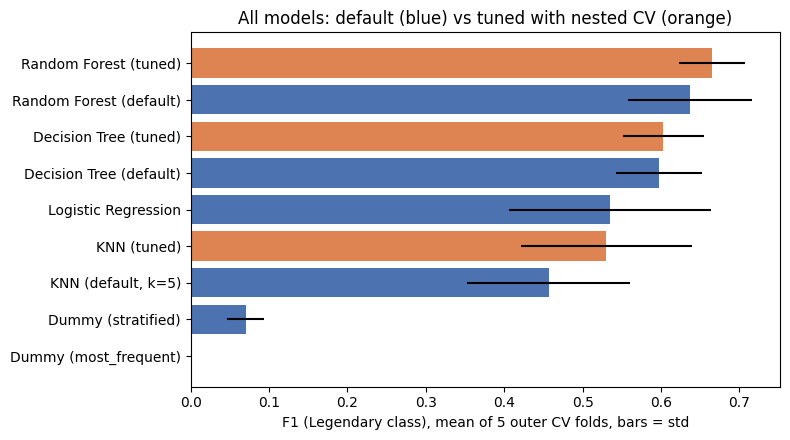

In [8]:
all_results = pd.concat([defaults, tuned]).sort_values("f1", ascending=False)
display(all_results)

order = all_results["f1"].sort_values()
colors = ["#DD8452" if "tuned" in n else "#4C72B0" for n in order.index]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(order.index, order.values, xerr=all_results.loc[order.index, "f1_std"], color=colors)
ax.set_xlabel("F1 (Legendary class), mean of 5 outer CV folds, bars = std")
ax.set_title("All models: default (blue) vs tuned with nested CV (orange)")
plt.tight_layout()
plt.savefig(FIG_DIR / "m4_all_models_f1.png", dpi=150)
plt.show()

## 7. What tuning did, and the final model

- **Random Forest** improved from F1 0.637 to 0.665. The clearest change was `class_weight="balanced"`, which was picked in every fold: it makes mistakes on the rare Legendary class cost more. The forest gives up some precision (0.917 to 0.750) to catch more Legendaries (recall 0.491 to 0.615). For this problem that is a sensible trade. Depth and leaf size changed between folds and the top four settings scored within about 0.05 of each other, so those two settings matter much less than `class_weight`.
- **Decision Tree** barely changed (0.597 to 0.603), and each fold picked different settings. A single tree is unstable with 96 Legendary examples, so tuning gave no reliable gain.
- **KNN** improved (0.457 to 0.530) but stays the weakest tuned model. It relies on distances between stats, and Legendary Pokémon are not neatly grouped together.
- The gap between the tuned Random Forest and the next best model (about 0.06 F1) is similar in size to the fold-to-fold spread (0.04 to 0.05). So the Random Forest looks best, but the margin is modest and I should not over-claim it.

**Decision (made before the test set is used):** the **tuned Random Forest** is my final model. It has the best nested-CV F1. Its settings come from one search on the whole training set: 200 trees, `class_weight="balanced"`, `max_depth=8`, `min_samples_leaf=1`. I will not change this choice after seeing test results. The test set is evaluated once, in the next part of this notebook.

This cell stores the final model so that later sections use exactly these settings. `best_estimator_` is the Random Forest from the search, already refitted on the whole training set. No test data is used.

In [9]:
final_model = final_search.best_estimator_   # refitted on the full training set only
rf_final = final_model.named_steps["model"]

print("Final model: Random Forest")
print("  n_estimators:    ", rf_final.n_estimators)
print("  class_weight:    ", rf_final.class_weight)
print("  max_depth:       ", rf_final.max_depth)
print("  min_samples_leaf:", rf_final.min_samples_leaf)
print("  random_state:    ", rf_final.random_state)
print("Test set used so far: no")

Final model: Random Forest
  n_estimators:     200
  class_weight:     balanced
  max_depth:        8
  min_samples_leaf: 1
  random_state:     42
Test set used so far: no
